In [1]:
import os; os.environ["JAX_PLATFORMS"] = "cpu"
import jax.numpy as jnp
import jax.random as jxr
import matplotlib.pyplot as plt
import seaborn as sns

import clds.utils as utils
from clds.simulate import simulate_hd_data, simulate_hd_dynamics
from clds.models import CLDS2
import clds.postprocessing as postprocessing

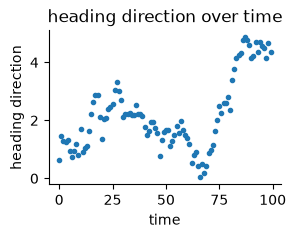

In [2]:
num_timesteps = 100
n_batches = 100
n_neurons = 10
epsilon = 0.1
noise_scale = 0.2 #! changed from 0.1
theta, X, Y = simulate_hd_data(num_timesteps, n_batches, n_neurons, epsilon, noise_scale, seed=0)

partition = int(0.8 * n_batches)
X_train, Y_train = X[:partition], Y[:partition]
X_test, Y_test = X[partition:], Y[partition:]

thetas_train = theta[:partition]
thetas_test = theta[partition:]

plt.figure(figsize=[3,2])
plt.plot(theta[0] % (2 * jnp.pi), '.')
# plt.plot(theta[1] % (2 * jnp.pi), '.')
plt.ylabel('heading direction')
plt.xlabel('time')
plt.title('heading direction over time');
sns.despine()

Text(0.5, 0.98, 'True As')

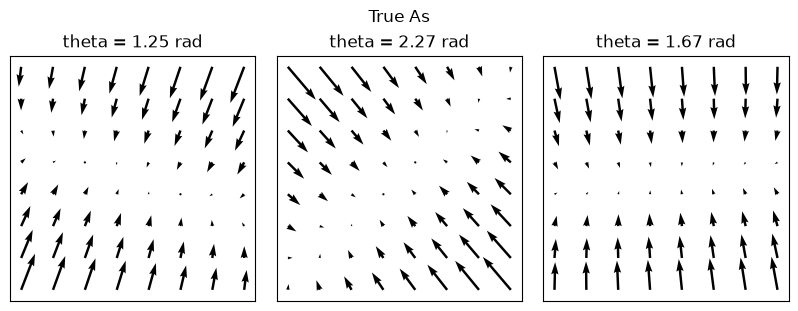

In [3]:
def plot_vector_field(A, ax):
    x = jnp.linspace(-1, 1, 8)
    y = jnp.linspace(-1, 1, 8)
    X, Y = jnp.meshgrid(x, y)
    U = A[0, 0] * X + A[0, 1] * Y
    V = A[1, 0] * X + A[1, 1] * Y

    # Thicken the arrows
    ax.quiver(X, Y, U, V, units='width', scale=8, width=0.01)

theta_indices = [3, 76, 58]

fig, axs = plt.subplots(ncols=3, figsize=[8,3], constrained_layout=True)
for i, _theta_ind in enumerate(theta_indices):
    _theta = theta[0][_theta_ind]
    true_As = simulate_hd_dynamics(theta[0], epsilon, noise_scale)[0]
    plot_vector_field(true_As[_theta_ind] - jnp.eye(2), axs[i])
    axs[i].set_title(f"theta = {_theta % (2*jnp.pi):.2f} rad")

for ax in axs:
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

fig.suptitle("True As")
# plt.savefig("figures/demo_HD_vector_field.eps", format='eps')

Text(0.5, 0.98, 'A prior samples')

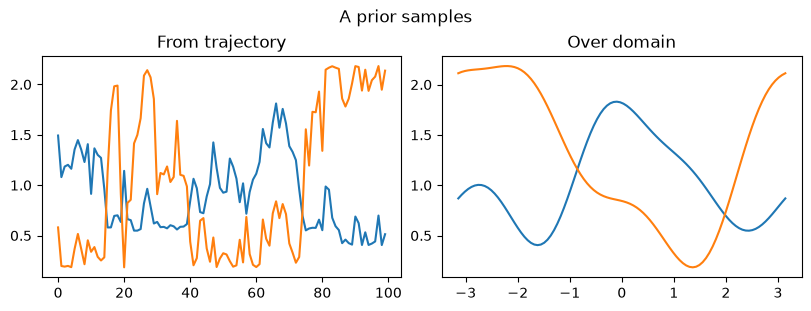

In [4]:
# Define model
latent_dim = 2

# _sigma, _kappa, _period = 0.5, 0.1, 2*jnp.pi
# torus_basis_funcs = utils.Tm_basis(5, M_conditions=1, sigma=_sigma, kappa=_kappa, period=_period)

basis = utils.initialize_basis(thetas_train[..., None], lengthscale=1.0, period=[2*jnp.pi])
model = CLDS2(
    state_dim=latent_dim, 
    emission_dim=n_neurons,
    basis=basis,
    gp_priors=["A", "b", "m"],
    use_dynamics_bias=True,
    use_emissions_bias=False,
    )

fig, (ax, ax2) = plt.subplots(figsize=[8,3], ncols=2, constrained_layout=True)
ax.plot(model.priors["A"].sample(jxr.PRNGKey(0), theta[0])[:,0,0]);
ax.plot(model.priors["A"].sample(jxr.PRNGKey(0), theta[0])[:,0,1]);
ax.set_title('From trajectory');
ax2.plot(jnp.linspace(-jnp.pi, jnp.pi, 100), model.priors["A"].sample(jxr.PRNGKey(0), jnp.linspace(-jnp.pi, jnp.pi, 100))[:,0,0]);
ax2.plot(jnp.linspace(-jnp.pi, jnp.pi, 100), model.priors["A"].sample(jxr.PRNGKey(0), jnp.linspace(-jnp.pi, jnp.pi, 100))[:,0,1]);
ax2.set_title('Over domain');
fig.suptitle('A prior samples')

# Fitting

  0%|          | 0/100 [00:00<?, ?it/s]

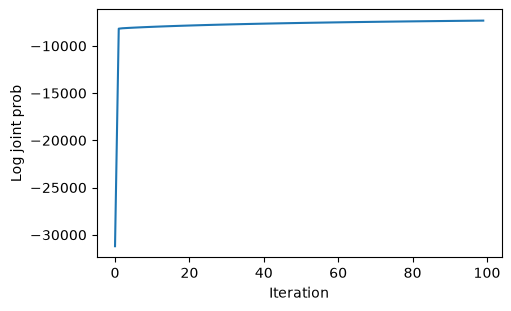

In [5]:
mask = jnp.ones_like(thetas_train, dtype=bool)
params, (marginal_log_liks, log_probs) = model.fit(emissions=Y_train, conditions=thetas_train, mask=mask, num_iters=100, seed=0)
fig, ax = plt.subplots(figsize=[5,3], constrained_layout=True)
ax.plot(log_probs)
ax.set_ylabel('Log joint prob')
ax.set_xlabel('Iteration');

# Show recovery

In [6]:
def find_similarity_transform(As_1, As_2):
    """
    Find T minimizing sum_t ||As_1[t] T - T As_2[t]||_F^2 subject to ||T||_F = 1,
    so that As_1 ~= T As_2 T^{-1}. As_1, As_2 have shape (T, D, D).

    With row-major vec, vec(A X) = (A kron I) vec(X) and vec(X B) = (I kron B^T) vec(X),
    so each step gives the linear constraint M_t vec(T) = 0, M_t = A1_t kron I - I kron A2_t^T.
    T is the eigenvector of sum_t M_t^T M_t with the smallest eigenvalue.
    """
    D = As_1.shape[-1]
    I = jnp.eye(D)
    Ms = jnp.einsum("tij,kl->tikjl", As_1, I) - jnp.einsum("ij,tlk->tikjl", I, As_2)
    Ms = Ms.reshape(-1, D * D, D * D)
    evals, evecs = jnp.linalg.eigh(jnp.einsum("tij,tik->jk", Ms, Ms))
    T = evecs[:, 0].reshape(D, D)

    # fix the arbitrary scale and sign: det(T) = 1 (for odd D; up to sign for even D)
    T = T / jnp.abs(jnp.linalg.det(T)) ** (1 / D)
    residual = jnp.linalg.norm(As_1 - T @ As_2 @ jnp.linalg.inv(T)) / jnp.linalg.norm(As_1)
    return T, residual

def find_scaling(bs_1, bs_2, T0):
    alpha = jnp.sum(bs_1 * (bs_2 @ T0.T)) / jnp.sum((bs_2 @ T0.T) ** 2)
    return alpha

## Over trajectories

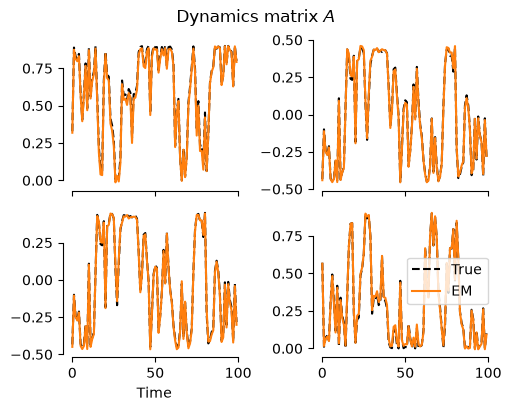

In [7]:
fig, axs = plt.subplots(ncols=latent_dim, nrows=latent_dim, figsize=(5, 4), constrained_layout=True);
true_As, true_bs, _, _, _ = simulate_hd_dynamics(theta[0], epsilon, noise_scale)
fit_As = model.weights_to_params(params, theta[0])[0]
init_As = model.weights_to_params(model.initial_params, theta[0])[0]
T, _ = find_similarity_transform(true_As, fit_As)
transformed_As = jnp.einsum("ij,tjk,ks->tis", T, fit_As, jnp.linalg.inv(T))

for i in range(2):
    for j in range(2):
        ax = axs[i,j]
        ax.plot(true_As[:,i,j], 'k--', label='True')
        # ax.plot(rotate(init_As, T)[:,i,j], label='init')
        ax.plot(transformed_As[:,i,j], label='EM', c='tab:orange')
        # ax.set_title(f'A[{i},{j}]')
axs[1,0].set_xlabel('Time')
axs[1,1].legend()

for ax in axs.flatten():
    sns.despine(ax=ax, trim=True, offset=True)
for ax in axs[0]:
    ax.set_xticklabels([])
    
fig.suptitle('Dynamics matrix $A$');

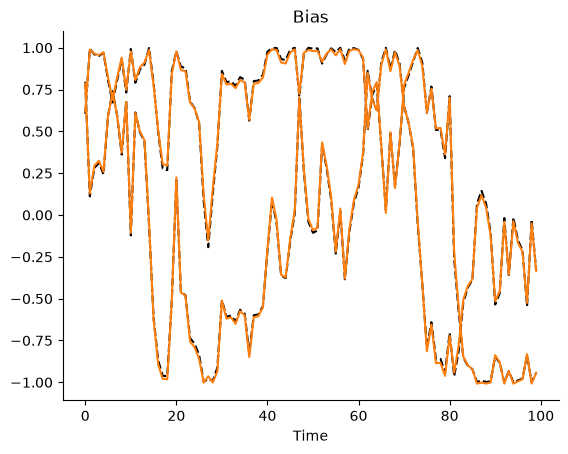

In [8]:
fit_bs = model.weights_to_params(params, theta[0])[2].squeeze()
alpha = find_scaling(true_bs, fit_bs, T)
transformed_bs = jnp.einsum("ij,tj->ti", alpha * T, fit_bs)

fig, ax = plt.subplots()
ax.plot(true_bs,'k--', label='True');
ax.plot(transformed_bs, c='tab:orange', label='EM');
ax.set_title("Bias")
ax.set_xlabel('Time')
sns.despine()

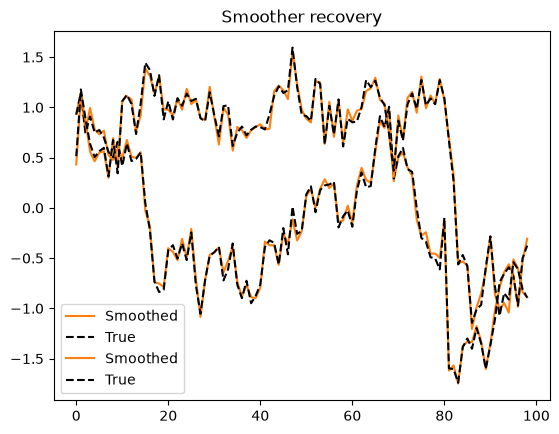

In [9]:
batch_id = 0
_, (filtered_means, _), (smoothed_means, smoothed_covs, _) = model.smoother(
    params, 
    emissions = Y_train[batch_id],
    inputs = theta[batch_id],
)

transformed_means = jnp.einsum("ij,tj->ti", alpha * T, smoothed_means)

fig, ax = plt.subplots()
for i in range(2):
    ax.plot(transformed_means[1:, i], color='tab:orange', label='Smoothed')
    ax.plot(X_train[batch_id, 1:, i], 'k--', label='True')
ax.set_title('Smoother recovery')
ax.legend();

Text(0.5, 0, 'Time')

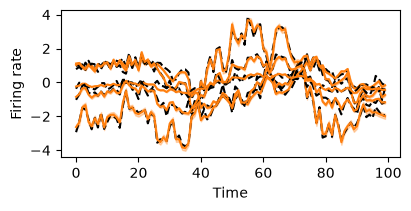

In [10]:
_, (filtered_means, _), (smoothed_means, smoothed_covs, _) = model.smoother(
    params, 
    emissions = Y_test[0],
    inputs = thetas_test[0],
)
Cs = params.emissions_weights #C_prior(params.emissions_weights, conditions)
if Cs.ndim == 2:
    Cs = jnp.tile(Cs[None, :, :], (num_timesteps, 1, 1))
reconstructed_ys = jnp.einsum('tnl,tl->tn', Cs, smoothed_means)
reconstructed_ys_covs = jnp.einsum('tnl,tlk,tmk->tnm', Cs, smoothed_covs, Cs)

fig, ax = plt.subplots(figsize=[4,2], constrained_layout=True);
for neuron_id in range(n_neurons)[::2]:
    ax.plot(Y_test[0][:100,neuron_id] , c='k', ls='--');
    ax.plot(reconstructed_ys[:100,neuron_id], c='tab:orange');
    ax.fill_between(
        jnp.arange(len(reconstructed_ys))[:100],
        reconstructed_ys[:100,neuron_id] - 2 * jnp.sqrt(reconstructed_ys_covs[:100,neuron_id,neuron_id]),
        reconstructed_ys[:100,neuron_id] + 2 * jnp.sqrt(reconstructed_ys_covs[:100,neuron_id,neuron_id]),
        alpha=0.3, color='tab:orange',
    )
ax.set_ylabel('Firing rate')
ax.set_xlabel('Time')
# plt.legend()
# ax.set_title('Reconstructed data, half the neurons');
# plt.savefig('figures/HD_reconstructed_data.eps')

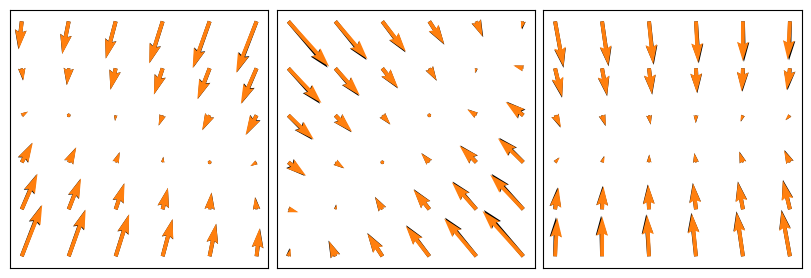

In [11]:
# Plot vector field given 2x2 matrix

def plot_vector_field(A, ax, color='k'):
    x = jnp.linspace(-1, 1, 6)
    y = jnp.linspace(-1, 1, 6)
    X, Y = jnp.meshgrid(x, y)
    U = A[0, 0] * X + A[0, 1] * Y
    V = A[1, 0] * X + A[1, 1] * Y

    # Thicken the arrows
    ax.quiver(X, Y, U, V, units='width', scale=6, width=0.015, color=color)

_As = model.weights_to_params(params, theta[0])[0]
_As = jnp.einsum("ij,tjk,ks->tis", T, _As, jnp.linalg.inv(T))

fig, axs = plt.subplots(ncols=3, figsize=[8,3], constrained_layout=True)
plot_vector_field(true_As[3] - jnp.eye(latent_dim), axs[0])
plot_vector_field(_As[3] - jnp.eye(latent_dim), axs[0], color='tab:orange')

plot_vector_field(true_As[76] - jnp.eye(latent_dim), axs[1])
plot_vector_field(_As[76] - jnp.eye(latent_dim), axs[1], color='tab:orange')

plot_vector_field(true_As[58] - jnp.eye(latent_dim), axs[2])
plot_vector_field(_As[58] - jnp.eye(latent_dim), axs[2], color='tab:orange')

for ax in axs:
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

# plt.savefig("figures/demo_HD_vector_field_recovery.eps", format='eps')

# Over range

In [12]:
theta_range = jnp.linspace(0, 2*jnp.pi, 200)

true_As, true_bs, _, _, _ = simulate_hd_dynamics(theta_range, epsilon, noise_scale)
fit_As, fit_Cs, fit_bs, fit_ds, fit_m0 = model.weights_to_params(params, theta_range)

T, _ = find_similarity_transform(true_As, fit_As)
transformed_As = jnp.einsum("ij,tjk,ks->tis", T, fit_As, jnp.linalg.inv(T))
transformed_bs = jnp.einsum("ij,tj->ti", T, fit_bs)

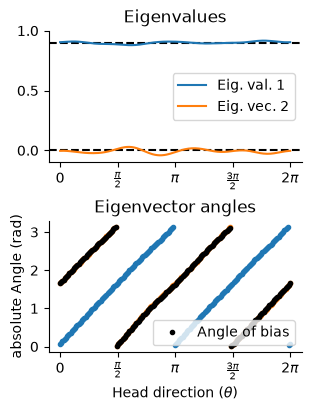

In [13]:
def get_angles(vs, correction=0):
    angles = jnp.arctan2(vs[:,1], vs[:,0]) + correction
    return jnp.where(angles < 0, angles + 2*jnp.pi, angles)

# Calculate eigenvalues and eigenvectors angles

eigvals, eigvecs = jnp.linalg.eig(fit_As)
true_eigvals, true_eigvecs = jnp.linalg.eig(true_As)

top_eigenval = jnp.where(eigvals.real[:,0] > eigvals.real[:,1], eigvals.real[:,0], eigvals.real[:,1])
bottom_eigenval = jnp.where(eigvals.real[:,0] < eigvals.real[:,1], eigvals.real[:,0], eigvals.real[:,1])

angles_1 = get_angles(eigvecs[:,:,0].real)
angles_2 = get_angles(eigvecs[:,:,1].real)

top_eigvec_angles = jnp.where(top_eigenval == eigvals.real[:,0], angles_1, angles_2)
bottom_eigvec_angles = jnp.where(bottom_eigenval == eigvals.real[:,0], angles_1, angles_2) 

# Plot

fig, axs = plt.subplots(figsize=[3,4], nrows=2, constrained_layout=True)
axs[0].plot(theta_range, top_eigenval, label='Eig. val. 1')
axs[0].plot(theta_range, bottom_eigenval, label='Eig. vec. 2')
axs[0].axhline(1-epsilon, c='k', ls='--', zorder=-1)
axs[0].axhline(0., c='k', ls='--', zorder=-1)
axs[0].set_ylim([-0.1,1.])
axs[0].legend()
axs[0].set_title('Eigenvalues')

axs[1].plot(theta_range, top_eigvec_angles  % jnp.pi, '.', c='tab:blue')
axs[1].plot(theta_range, bottom_eigvec_angles  % jnp.pi, '.', c='tab:orange')
axs[1].set_title('Eigenvector angles')
axs[1].set_ylabel('absolute Angle (rad)')
b_theta_angles = get_angles(fit_bs)
b_theta_angles = jnp.where(b_theta_angles < 0, b_theta_angles + 2*jnp.pi, b_theta_angles) # Correct for negative angles

axs[1].plot(theta_range, b_theta_angles % jnp.pi, '.', c='k', label='Angle of bias')
axs[1].legend()
axs[1].set_xlabel(r'Head direction ($\theta$)')

for ax in axs:
    sns.despine(ax=ax)
    ax.set_xticks([0, jnp.pi/2, jnp.pi, 3*jnp.pi/2, 2*jnp.pi])
    ax.set_xticklabels(['0', r"$\frac{\pi}{2}$", '$\pi$', r"$\frac{3\pi}{2}$", '$2\pi$'])

# Postprocessing analysis

Fixed points and composite dynamics

In [14]:
# Rotate latents to have identity Q, and calculate fixed points 
fixed_points = postprocessing.get_fixed_points(model, params, theta_range, ROTATE=True)
fixed_points = jnp.einsum("ij,tj->ti", T, fixed_points)

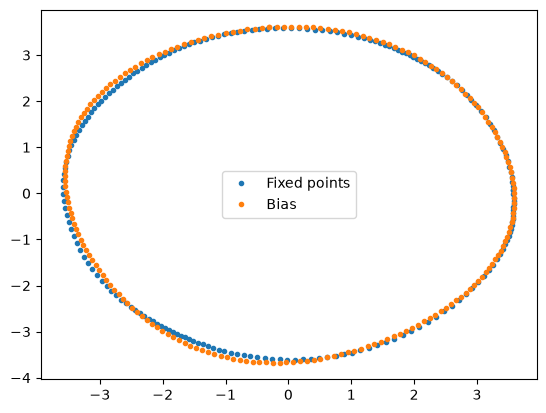

In [15]:
plt.plot(*fixed_points.T, '.', label='Fixed points')
plt.plot(*fit_bs.T, '.', label='Bias')
plt.legend();

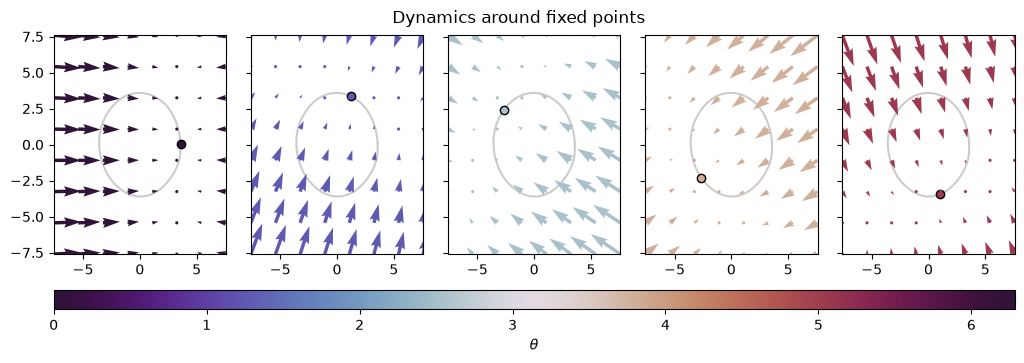

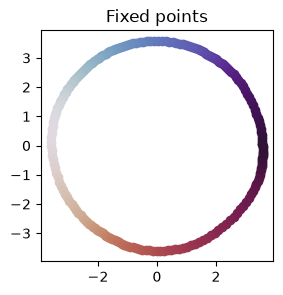

In [16]:
# Plot vector fields per fixed point

cmap = plt.cm.twilight_shifted
colors = cmap(theta_range/(2*jnp.pi))

# =============================================================================

x_lims = (jnp.amin(fixed_points[:,0])-4, jnp.amax(fixed_points[:,0])+4)
y_lims = (jnp.amin(fixed_points[:,1])-4, jnp.amax(fixed_points[:,1])+4)

def plot_vector_field(A, ax, center=jnp.zeros((2,)), color='k'):
    x = jnp.linspace(*x_lims, 8)
    y = jnp.linspace(*y_lims, 8)
    X, Y = jnp.meshgrid(x, y)
    U = A[0, 0] * (X - center[0]) + A[0, 1] * (Y - center[1])
    V = A[1, 0] * (X - center[0]) + A[1, 1] * (Y - center[1])

    # Thicken the arrows
    ax.quiver(X, Y, U, V, units='width', scale=70, width=0.02, color=color)

# sns.set_style('white')
fig = plt.figure(figsize=[10,3.5], constrained_layout=True)

ncols = 5
gs = fig.add_gridspec(1, ncols, wspace=0.1)
axs = [fig.add_subplot(gs[0, i]) for i in range(ncols)]

indices = jnp.linspace(0, len(fixed_points), len(axs), endpoint=False, dtype=int)
for i, ax in zip(indices, axs):
    ax.scatter(*fixed_points[i], color=colors[i], edgecolors='k')
    ax.plot(*fixed_points.T, c='k', alpha=0.2, zorder=-1)
    plot_vector_field(transformed_As[i] - jnp.eye(2), ax=ax, center=fixed_points[i], color=colors[i])

for ax in axs:
    if ax is not axs[0]:
        ax.set_yticklabels([])
    ax.set_xlim(*x_lims)
    ax.set_ylim(*y_lims)

# Add colorbar
norm = plt.Normalize(0, 2*jnp.pi)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
fig.colorbar(sm, ax=axs, orientation='horizontal', label=r'$\theta$', aspect=50) # shrink=1.0

fig.suptitle('Dynamics around fixed points')
plt.show()

# =============================================================================

fig, ax = plt.subplots(figsize=[3,3])
for i, fp in enumerate(fixed_points):
    ax.scatter(*fp, color=colors[i])
ax.set_title('Fixed points')
plt.show()

## Composite dynamics

In [17]:
# import postprocessing
x_bin_edges, y_bin_edges, composite_Fs, U_per_bin, bin_counts = postprocessing.compute_composite_dynamics(
    model, params, theta_range, Y_train, thetas_train
)

100%|██████████| 80/80 [01:43<00:00,  1.30s/it]


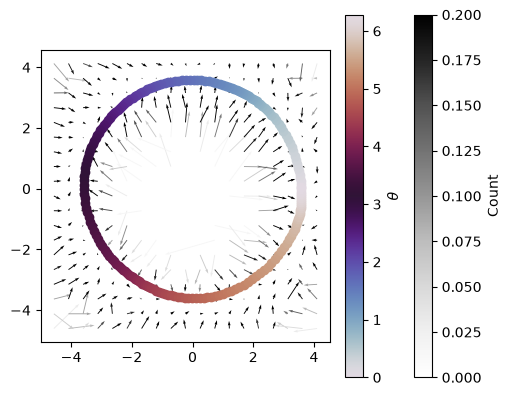

In [18]:
# plot composite dynamics

cmap = plt.cm.twilight
colors = cmap(jnp.linspace(0,2*jnp.pi,len(fixed_points))/(2*jnp.pi))
cmap_count = plt.cm.Greys
norm_count = plt.Normalize(0, 0.2)

fig, ax = plt.subplots(figsize=[5,4], constrained_layout=True);
ax.quiver(
    *jnp.meshgrid(x_bin_edges, y_bin_edges), *composite_Fs,
    bin_counts.T/jnp.amax(bin_counts), cmap=cmap_count, norm=norm_count, 
    scale=20
    )

for i, fp in enumerate(fixed_points):
    ax.scatter(*fp, color=colors[i])
ax.set_aspect('equal')

# Color of quiver is set by count, lighter means less count (thus more uncertain about calculation)
sm_count = plt.cm.ScalarMappable(cmap=cmap_count, norm=norm_count)
cbar_quiver = plt.colorbar(sm_count, ax=ax, orientation='vertical')
cbar_quiver.set_label('Count')

# Add colorbar for scatter
norm = plt.Normalize(0, 2*jnp.pi)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar_scatter = plt.colorbar(sm, ax=ax, orientation='vertical')
cbar_scatter.set_label(r'$\theta$')